In [63]:
import numpy as np

sigma = 1 #k_BT
N = 3
tau_0 = 1
beta = 1 # k_BT ^-1
def D(sigma, tau_0=tau_0, beta=beta):
    return 1 / (2 * tau_0) * (1 + beta**2 * sigma**2 / 2) ** (1/2) * np.exp(-7 * beta**2 * sigma**2 / 4)

def diffusion_rate_coefficient(sigma, tau_0=tau_0, beta=beta, k=1, n_steps=100, n_nucleotides=100):
    diffusion_coefficient = D(sigma, tau_0, beta)
    return diffusion_coefficient / (k**2 * (n_steps / n_nucleotides)**2)

def E_ns(sigma, tau_3d, tau_0, beta=beta):
    return 1/beta * (np.log(tau_3d / tau_0) - 1/2 * (sigma * beta)**2)

def specific_binding_energy(sigma, tau_3d, tau_0, size=1):
    mean_binding_energy = E_ns(sigma, tau_3d, tau_0, beta=beta)
    return np.random.normal(mean_binding_energy, sigma, size)

def generate_transition_matrix(sigma, tau_0_diffusion, tau_0_dissociation, beta=beta, tau_3d=0.1, n_states=N, n_nucleotides=N, rate_absorption=1):
    L = np.zeros((N, N))
    specific_binding_energies = specific_binding_energy(sigma, tau_3d=tau_3d, tau_0=tau_0_dissociation, size=n_states)
    for i in range(N):
        for j in range(N):
            if j == 0 and i == 0:
                L[i, j] -= diffusion_rate_coefficient(sigma, tau_0_diffusion, beta, n_steps=N, n_nucleotides=n_nucleotides) 
            if j == i and i != 0:
                nonspecific_binding_energy = E_ns(sigma, tau_3d=1, tau_0=tau_0, beta=beta)
                k_unbinding = 1 / tau_0_dissociation * np.exp(-beta * (nonspecific_binding_energy - specific_binding_energies[j]))
                L[i, j] -= 2 * diffusion_rate_coefficient(sigma, tau_0_diffusion, beta, n_steps=n_states, n_nucleotides=n_nucleotides) + k_unbinding
            if j == i - 1 or j == i + 1:
                L[i, j] += diffusion_rate_coefficient(sigma, tau_0_diffusion, beta, n_steps=n_states, n_nucleotides=n_nucleotides)
            if i == 0 and i != j:
                nonspecific_binding_energy = E_ns(sigma, tau_3d=1, tau_0=tau_0, beta=beta)
                k_unbinding = 1 / tau_0_dissociation * np.exp(-beta * (nonspecific_binding_energy -specific_binding_energies[j]))
                L[i, j] += k_unbinding
            if i == N-1 and j == N-1:
                L[i, j] += diffusion_rate_coefficient(sigma, tau_0_diffusion, beta, n_steps=n_states, n_nucleotides=n_nucleotides) - rate_absorption
            if i == 0 and j == N-1:
                L[i, j] += rate_absorption
    return L


In [121]:
import matplotlib.pyplot as plt
import mpmath
N=3
rate_absorption = 1
activation_rates = []
diffusion_rate_coefficients = []
falling_coefficients = []
for sigma in np.linspace(0, 5, 100):
    tau_0_diffusion = 1e-3
    tau_3d = 0.5
    tau_0_dissociation = 1e-3
    specific_binding_energies = specific_binding_energy(sigma, tau_3d=tau_3d, tau_0=tau_0_dissociation, size=N)
    tau_0_dissociation = 1
    L = generate_transition_matrix(sigma, tau_0_diffusion=tau_0_diffusion, tau_0_dissociation=tau_0_dissociation, beta=beta, tau_3d = tau_3d, n_states=N, n_nucleotides=N, rate_absorption = rate_absorption)
    for i in range(N):
        L[N-1, i] = 1
    p = np.zeros(N)
    p[N-1] = 1
    p_ss = mpmath.lu_solve(L,p)
    activation_rates.append(p_ss[N-1] * rate_absorption)
    nonspecific_binding_energy = E_ns(sigma, tau_3d=1, tau_0=tau_0, beta=beta)
    k_unbinding = 1 / tau_0_dissociation * np.exp(-beta * (nonspecific_binding_energy -specific_binding_energies[0]))
    d = diffusion_rate_coefficient(sigma, tau_0_diffusion, beta, n_steps=N, n_nucleotides=N)
    diffusion_rate_coefficients.append(d)
    falling_coefficients.append(k_unbinding)



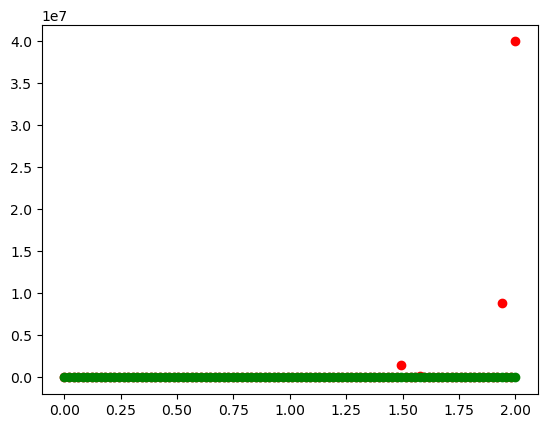

In [123]:
plt.scatter(np.linspace(0, 2, 100), falling_coefficients, color='red')
plt.scatter(np.linspace(0, 2, 100), diffusion_rate_coefficients, color='green')
# plt.yscale('log')

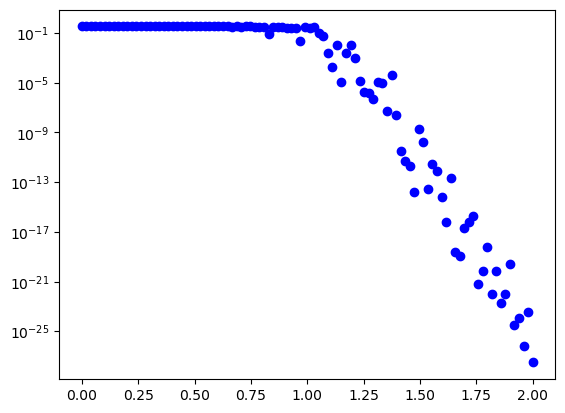

In [103]:
plt.scatter(np.linspace(0, 2, 100), activation_rates, color='blue')  
plt.yscale('log')